## Actividad Práctica Completa: Procesamiento y Ciencia de Datos con Dataset Sintético

**Materia:** Procesamiento de datos · **Tecnicatura:** Data Science and AI
**Autora:** Taisiia Bogatyreva · **Fecha:** 14.10.2026

In [1]:
import pandas as pd
import numpy as np

np.random.seed(42)
n_samples = 1000

# 1. Identificadores de clientes y duplicados
ids = np.random.randint(1000, 1500, size=n_samples)

# 2. Fechas con formatos heterogéneos e inconsistencias
fechas_base = ['2023-01-15', '15/02/2023', '2023.03.10', '10-Apr-2023', '1900-01-01', '2035-12-31', None]
fechas = np.random.choice(fechas_base, size=n_samples)

# 3. Edades con valores fuera de rango (-8, 150) y faltantes
edades = np.random.normal(loc=40, scale=12, size=n_samples)
edades[10:20] = -8
edades[21:30] = 150
edades[31:45] = np.nan

# 4. Ingreso Mensual guardado como texto con símbolos y errores
ingresos_num = np.random.exponential(scale=3000, size=n_samples) + 500
ingresos_str = [f"${x:,.2f}" for x in ingresos_num]
for i in range(50, 70):
    ingresos_str[i] = "Gratis"
for i in range(71, 90):
    ingresos_str[i] = np.nan


In [2]:
# 5. Monto del Crédito con asimetría positiva y outliers extremos
monto_credito = np.random.lognormal(mean=9, sigma=1.2, size=n_samples)
monto_credito[100:105] = 500000.0  # Outliers extremos

# 6. Estado Civil con inconsistencias de espacios y minúsculas/mayúsculas
estados = [' Soltero ', 'soltero', 'SOLTERO', 'Casado', 'CASADO', 'Divorciado ', 'Viudo']
estado_civil = np.random.choice(estados, size=n_samples)

# 7. Nivel Educativo (Variable Ordinal)
educacion = np.random.choice(['Primaria', 'Secundaria', 'Universitario', 'Postgrado'], size=n_samples)

# 8. Columna con >50% de valores faltantes
notas_auditoria = [np.nan] * n_samples
for i in range(0, 100):
    notas_auditoria[i] = "Revisión manual requerida"

# 9. Target Leakage (Variable futura que revela el target directamente)
target = np.random.choice([0, 1], size=n_samples, p=[0.94, 0.06])
dias_mora_posteriores = np.where(target == 1, np.random.randint(31, 180, size=n_samples), 0)

# Construcción del DataFrame original
df_sintetico = pd.DataFrame({
    'id_cliente': ids,
    'fecha_alta': fechas,
    'edad': edades,
    'ingreso_mensual_str': ingresos_str,
    'monto_credito': monto_credito,
    'estado_civil': estado_civil,
    'nivel_educativo': educacion,
    'notas_auditoria': notas_auditoria,
    'dias_mora_posteriores': dias_mora_posteriores, # Fuga de datos
    'incumplimiento': target
})

# Inyección deliberada de duplicados exactos
df_sintetico = pd.concat([df_sintetico, df_sintetico.iloc[0:20]], ignore_index=True)
df_sintetico.to_csv('dataset_riesgo_crediticio_dirty.csv', index=False)
print("Dataset sintético 'dataset_riesgo_crediticio_dirty.csv' generado exitosamente.")


Dataset sintético 'dataset_riesgo_crediticio_dirty.csv' generado exitosamente.


### Paso 1: Exploración Inicial, Diagnóstico de Calidad y Auditoría Previa

In [3]:

# Carga e inspección básica
df_raw = pd.read_csv('dataset_riesgo_crediticio_dirty.csv')
print("--- Diagnóstico Estructural Inicial ---")
print(df_raw.info())
print("\n--- Distribución de la Variable Objetivo ---")
print(df_raw['incumplimiento'].value_counts(normalize=True))

# Eliminación preventiva de Target Leakage
df_clean = df_raw.drop(columns=['dias_mora_posteriores']).copy()

--- Diagnóstico Estructural Inicial ---
<class 'pandas.DataFrame'>
RangeIndex: 1020 entries, 0 to 1019
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   id_cliente             1020 non-null   int64  
 1   fecha_alta             868 non-null    str    
 2   edad                   1006 non-null   float64
 3   ingreso_mensual_str    1001 non-null   str    
 4   monto_credito          1020 non-null   float64
 5   estado_civil           1020 non-null   str    
 6   nivel_educativo        1020 non-null   str    
 7   notas_auditoria        120 non-null    str    
 8   dias_mora_posteriores  1020 non-null   int64  
 9   incumplimiento         1020 non-null   int64  
dtypes: float64(2), int64(3), str(5)
memory usage: 79.8 KB
None

--- Distribución de la Variable Objetivo ---
incumplimiento
0    0.941176
1    0.058824
Name: proportion, dtype: float64


Se encontró que la variable objetivo incumplimiento presenta un fuerte desbalanceo: aproximadamente 94 % de los clientes cumple con el pago y solo 6 % incumple. El diagnóstico de calidad (cifras sobre las 1000 filas únicas) mostró problemas en las cuatro dimensiones. Completitud: notas_auditoria tiene 90 % de nulos y fecha_alta 14,9 %; edad e ingreso_mensual también presentan faltantes. Consistencia: estado_civil aparece con 7 variantes para solo 4 categorías reales, las fechas usan varios formatos distintos y el ingreso es texto con símbolo $ y la palabra “Gratis” (20 casos). Validez: hay edades imposibles (-8 en 10 casos y 150 en 9) y fechas implausibles (1900-01-01 y 2035-12-31). Unicidad: se hallaron 20 filas duplicadas exactas. Además, la auditoría identificó que dias_mora_posteriores es una variable de fuga de información (Target Leakage), ya que registra datos que solo existen después del incumplimiento y no estarían disponibles al decidir el crédito; por ello se eliminó del conjunto de variables independientes, evitando un rendimiento artificialmente alto. Cabe destacar que las fechas implausibles se detectaron pero no se corrigieron, ya que fecha_alta no se utiliza en el modelo.

### Paso 2: Limpieza Operativa, Deduplicación y Estandarización

In [4]:
df_clean = df_raw.drop(columns=['dias_mora_posteriores']).copy()

# 1. Deduplicación
df_clean = df_clean.drop_duplicates(keep='first').reset_index(drop=True)

# 2. Normalización de texto
df_clean['estado_civil'] = df_clean['estado_civil'].astype(str).str.strip().str.title()

# 3. Limpieza y casting de valores monetarios
df_clean['ingreso_mensual'] = (
    df_clean['ingreso_mensual_str']
    .astype(str)
    .str.replace('$', '', regex=False)
    .str.replace(',', '', regex=False)
    .str.replace('Gratis', '0', regex=False)
)
df_clean['ingreso_mensual'] = pd.to_numeric(df_clean['ingreso_mensual'], errors='coerce')
df_clean = df_clean.drop(columns=['ingreso_mensual_str'])

# 4. Homogeneización de fechas
df_clean['fecha_alta'] = pd.to_datetime(df_clean['fecha_alta'], format='mixed', errors='coerce')

# 5. Corrección de rango de edad
df_clean['edad'] = np.where(
    (df_clean['edad'] < 18) | (df_clean['edad'] > 100),
    np.nan,
    df_clean['edad']
)

print(df_clean['edad'].isnull().sum())
print(df_clean['ingreso_mensual'].isnull().sum())

59
19


In [5]:
print(df_clean.shape)

(1000, 9)


In [6]:
print(df_clean['estado_civil'].unique())

<StringArray>
['Viudo', 'Divorciado', 'Casado', 'Soltero']
Length: 4, dtype: str


In [7]:
print(df_clean.dtypes)

id_cliente                  int64
fecha_alta         datetime64[us]
edad                      float64
monto_credito             float64
estado_civil                  str
nivel_educativo               str
notas_auditoria               str
incumplimiento              int64
ingreso_mensual           float64
dtype: object


In [8]:
print(df_clean['edad'].min())
print(df_clean['edad'].max())

18.03240523772252
78.31729081413833


In [9]:
print(df_clean['fecha_alta'].isnull().sum())

149


Se detectaron cinco problemas de calidad: filas duplicadas, inconsistencias de formato en estado_civil (espacios y mayúsculas/minúsculas), ingresos almacenados como texto con símbolos monetarios y la palabra “Gratis”, fechas con formatos heterogéneos y edades fuera de rango biológico (-8 y 150). Se aplicó drop_duplicates() redujo el conjunto de 1020 a 1000 filas… Se marcaron como faltantes 45 edades fuera de [18, 100]: las 19 inyectadas (-8 y 150) y 26 edades legítimas pero menores de 18, consecuencia de aplicar un límite fijo a una distribución normal. Estas correcciones garantizan consistencia, validez y unicidad, condiciones necesarias para cualquier análisis posterior. Cabe destacar que interpretar “Gratis” como 0 es una suposición de negocio que debería validarse.

### Paso 3: Visualización y Tratamiento de Datos Faltantes

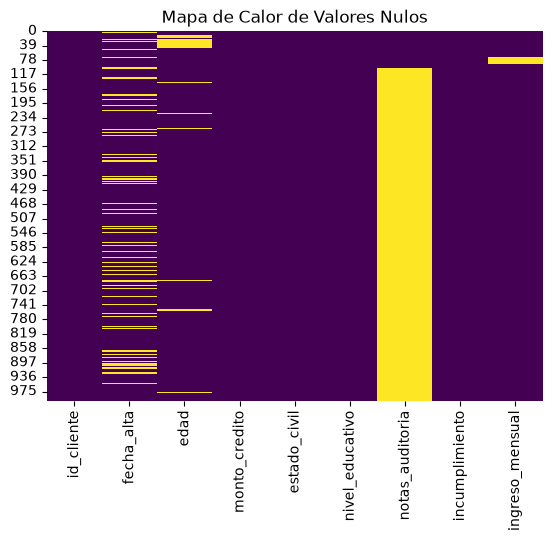

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt

# Visualización de matriz de nulos
sns.heatmap(df_clean.isnull(), cbar=False, cmap='viridis')
plt.title('Mapa de Calor de Valores Nulos')
plt.show()

# 1. Eliminación por umbral (columnas con >50% de nulos)
umbral_50 = len(df_clean) * 0.5
df_clean = df_clean.dropna(axis=1, thresh=umbral_50)

# 2. Imputación condicional de edad por grupo educativo
df_clean['edad'] = df_clean.groupby('nivel_educativo')['edad'].transform(lambda x: x.fillna(x.median()))

# 3. Imputaciones simples
df_clean['ingreso_mensual'] = df_clean['ingreso_mensual'].fillna(df_clean['ingreso_mensual'].median())
df_clean['estado_civil'] = df_clean['estado_civil'].fillna(df_clean['estado_civil'].mode()[0])




Tras la limpieza se observaron valores faltantes en edad (59, de los cuales 45 provienen del filtrado de rango) e ingreso_mensual (19), y la columna notas_auditoria presentaba 90 % de nulos (900 de 1000 filas). Respecto a los mecanismos de nulos: en este dataset los faltantes se inyectaron por posición, sin relación con otras variables ni con su propio valor, por lo que fecha_alta, edad e ingreso_mensual se consideran MCAR. En datos reales se sospecharía MAR si la ausencia dependiera de otra variable observada (por ejemplo, que ciertos niveles educativos omitan el ingreso), lo cual se verifica comparando las demás variables entre filas con y sin dato; MNAR (por ejemplo, que quienes tienen ingresos muy altos no lo declaren) no puede demostrarse solo con los datos observados y obliga a ser prudente con la imputación. Se eliminó notas_auditoria con dropna(axis=1, thresh=...), pues carece de valor predictivo. La edad se imputó con la mediana dentro de cada nivel_educativo (groupby().transform()), que preserva mejor la distribución que una mediana global; ingreso_mensual se imputó con la mediana (robusta ante valores extremos) y estado_civil con la moda. No se eliminaron filas, para no perder información. Como limitación, la imputación se realizó antes de la partición Train/Test, lo que introduce una fuga leve de información (ver observaciones finales). Las columnas fecha_alta conserva sus faltantes porque no se usa en el modelo.

### Paso 4: Detección y Tratamiento de Outliers

In [11]:
from scipy import stats

# Identificación por Z-Score en ingreso_mensual
z_scores = np.abs(stats.zscore(df_clean['ingreso_mensual']))
print(f"Outliers detectados por Z-Score (>3): {len(df_clean[z_scores > 3])}")

# Tratamiento por Winsorización en monto_credito (Percentiles 1% y 99%)
p1 = df_clean['monto_credito'].quantile(0.01)
p99 = df_clean['monto_credito'].quantile(0.99)
df_clean['monto_credito_winsorized'] = np.clip(df_clean['monto_credito'], p1, p99)

Outliers detectados por Z-Score (>3): 18


In [12]:
print(df_clean.columns.tolist())

['id_cliente', 'fecha_alta', 'edad', 'monto_credito', 'estado_civil', 'nivel_educativo', 'incumplimiento', 'ingreso_mensual', 'monto_credito_winsorized']


In [13]:
df_clean[['edad', 'ingreso_mensual', 'monto_credito_winsorized', 'estado_civil', 'nivel_educativo']].isnull().sum()

edad                        0
ingreso_mensual             0
monto_credito_winsorized    0
estado_civil                0
nivel_educativo             0
dtype: int64

Con el método Z-Score (|Z| > 3) se detectaron 18 valores atípicos en ingreso_mensual. Para monto_credito, de distribución asimétrica y con valores extremos (500 000), se aplicó winsorización: los valores se limitaron a los percentiles 1 y 99 (≈ 409,37 y ≈ 131 296,13) con np.clip(). A diferencia de eliminar filas, la winsorización conserva todas las observaciones y reduce la influencia de los extremos sobre el modelo.

In [14]:
# Detección por IQR en monto_credito
q1 = df_clean['monto_credito'].quantile(0.25)
q3 = df_clean['monto_credito'].quantile(0.75)

limite_inf = q1 - 1.5 * (q3 - q1)
limite_sup = q3 + 1.5 * (q3 - q1)

outliers_iqr = df_clean[(df_clean['monto_credito'] < limite_inf) | (df_clean['monto_credito'] > limite_sup)]
print(f"Límites IQR: [{limite_inf:.2f}, {limite_sup:.2f}]")
print(f"Outliers detectados por IQR: {len(outliers_iqr)}")

Límites IQR: [-19271.02, 41334.23]
Outliers detectados por IQR: 101


Se aplicaron dos métodos de detección. Con Z-Score (|Z| > 3) se identificaron 18 valores atípicos en ingreso_mensual. Con el rango intercuartílico (IQR), en monto_credito, cuyos límites fueron [-19 271,02; 41 334,23], se detectaron 101 valores atípicos. En esta variable el Z-Score solo detecta 8, porque la distribución es muy asimétrica y los valores extremos inflan la media y la desviación estándar; el IQR, basado en cuartiles, es más robusto, por lo que resulta más adecuado. Para tratar los extremos se aplicó winsorización con np.clip() en los percentiles 1 y 99 (≈ 409,37 y ≈ 131 296,13), que conserva todas las observaciones y limita el efecto de los valores más extremos (como los 500 000 inyectados). Cabe destacar que la winsorización en estos percentiles es más moderada que el criterio IQR: muchos valores altos permanecen, lo cual es razonable en una distribución lognormal donde los montos grandes son legítimos.

### Paso 5: Partición Estratificada y Aisle de Datos (Train-Test Split)

In [15]:
from sklearn.model_selection import train_test_split

X = df_clean[['edad', 'ingreso_mensual', 'monto_credito_winsorized', 'estado_civil', 'nivel_educativo']]
y = df_clean['incumplimiento']

# Partición estratificada obligatoria
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Tamaño Train: {X_train.shape}, Tamaño Test: {X_test.shape}")

Tamaño Train: (800, 5), Tamaño Test: (200, 5)


In [16]:
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

incumplimiento
0    0.9425
1    0.0575
Name: proportion, dtype: float64
incumplimiento
0    0.94
1    0.06
Name: proportion, dtype: float64


El conjunto se dividió en 80 % entrenamiento (800 filas) y 20 % prueba (200 filas) con train_test_split(stratify=y, random_state=42). La estratificación mantuvo la proporción de la clase minoritaria: 5,75 % en Train y 6,00 % en Test. La partición se realizó antes de las transformaciones (escalado y codificación) para que el conjunto de prueba no influya en los parámetros del preprocesamiento.

### Paso 6: Transformación de Variables e Integración en Pipeline

In [17]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, PowerTransformer

# Definición de columnas
num_cols = ['edad', 'ingreso_mensual']
cat_nominal = ['estado_civil']
cat_ordinal = ['nivel_educativo']

orden_educacion = [['Primaria', 'Secundaria', 'Universitario', 'Postgrado']]

# Ensamblado del preprocesador
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('pow', PowerTransformer(method='yeo-johnson'), ['monto_credito_winsorized']),
        ('cat_nom', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), cat_nominal),
        ('cat_ord', OrdinalEncoder(categories=orden_educacion), cat_ordinal)
    ]
)

# Ajuste EXCLUSIVO sobre Train y transformación de ambos sets
X_train_trans = preprocessor.fit_transform(X_train)
X_test_trans = preprocessor.transform(X_test)

In [18]:
print(X_train_trans.shape)
print(X_test_trans.shape)

(800, 7)
(200, 7)



Se construyó un ColumnTransformer con: StandardScaler para edad e ingreso_mensual, PowerTransformer (Yeo-Johnson) para monto_credito_winsorized por su asimetría, OneHotEncoder(drop='first') para estado_civil (variable nominal, evitando colinealidad) y OrdinalEncoder para nivel_educativo, respetando el orden Primaria < Secundaria < Universitario < Postgrado. El resultado son 7 columnas (2 + 1 + 3 + 1). El método fit se aplicó solo sobre Train, porque durante el ajuste el escalador calcula parámetros (media y desviación estándar) que, si se calcularan con Test, filtrarían información del conjunto de evaluación y producirían métricas optimistas. Al conjunto de prueba solo se le aplicó transform.

### Paso 7: Tratamiento de Desbalanceo con SMOTE, Entrenador y Evaluación

In [19]:
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_curve, auc

# 1. SMOTE exclusivo en Train
smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train_trans, y_train)

# 2. Entrenamiento de Modelo Cost-Sensitive
clf = RandomForestClassifier(random_state=42, class_weight='balanced')
clf.fit(X_train_res, y_train_res)

# 3. Predicción de probabilidades en Test
y_probs = clf.predict_proba(X_test_trans)[:, 1]

# 4. Ajuste de Umbral de Decisión (Moving Threshold a 0.25)
y_pred_custom = (y_probs >= 0.25).astype(int)

# Evaluación de resultados
print("--- Matriz de Confusión (Umbral 0.25) ---")
print(confusion_matrix(y_test, y_pred_custom))

print("\n--- Reporte de Clasificación ---")
print(classification_report(y_test, y_pred_custom))

precision, recall, _ = precision_recall_curve(y_test, y_probs)
pr_auc = auc(recall, precision)
print(f"Área Bajo la Curva Precision-Recall (PR-AUC): {pr_auc:.4f}")

--- Matriz de Confusión (Umbral 0.25) ---
[[150  38]
 [ 12   0]]

--- Reporte de Clasificación ---
              precision    recall  f1-score   support

           0       0.93      0.80      0.86       188
           1       0.00      0.00      0.00        12

    accuracy                           0.75       200
   macro avg       0.46      0.40      0.43       200
weighted avg       0.87      0.75      0.81       200

Área Bajo la Curva Precision-Recall (PR-AUC): 0.0445


Se aplicó SMOTE exclusivamente sobre Train, se entrenó un RandomForestClassifier con class_weight='balanced' y se redujo el umbral de decisión a 0,25 para favorecer el Recall. En el conjunto de prueba la matriz de confusión fue [[150, 38], [12, 0]]: el modelo no detectó ninguno de los 12 incumplimientos (Recall = 0) y generó 38 falsos positivos. El PR-AUC fue 0,0445, cercano al nivel base (0,06, la proporción de positivos). Este resultado es esperable, pues en el dataset sintético el objetivo se generó aleatoriamente y no depende de las variables; por tanto, el pipeline funciona correctamente, pero no hay patrón que aprender. La exactitud (0,75) es engañosa: un modelo que siempre prediga “0” lograría 0,94. Por eso se evalúa con PR-AUC y F1. Cabe destacar que, al ser el objetivo aleatorio, pequeños cambios en las versiones de las librerías alteran ligeramente las métricas (en otra ejecución, en Google Colab, se obtuvo [[147, 41], [12, 0]] y PR-AUC 0,0394), sin modificar la conclusión. Las métricas presentadas corresponden a un entorno con scikit-learn 1.9.1, imbalanced-learn 0.14.2, numpy 2.5.4 y pandas 3.0.6.

El pipeline transformó un dataset con errores deliberados en un conjunto limpio, sin fuga de información en el modelado y listo para Machine Learning. Como limitaciones: (1) la imputación y los percentiles de winsorización se calcularon con todo el dataset antes de la partición, lo que constituye una fuga leve; lo correcto sería calcularlos solo con Train, idealmente dentro de un Pipeline; (2) SMOTE y class_weight='balanced' abordan el desbalanceo dos veces, y bastaría con uno; (3) el bajo desempeño se debe a que el objetivo sintético es aleatorio, no a un fallo del procesamiento.

In [20]:
print(X_train_trans.shape, X_test_trans.shape)
print(p1, p99)

(800, 7) (200, 7)
409.37163631176526 131296.12675983913


In [21]:
import sklearn, imblearn, numpy, pandas
print(sklearn.__version__, imblearn.__version__, numpy.__version__, pandas.__version__)

1.9.1 0.14.2 2.5.4 3.0.6
